<a href="https://colab.research.google.com/github/alchemy110/deepchem/blob/master/proj_sara1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import numpy as np
import matplotlib.pyplot as plt

In [26]:
ROWS, COLS = 4, 4
N_STATES = ROWS * COLS # 16 states, row-major indexing 0...15
N_ACTIONS = 4 # 0=up, 1=right, 2=down, 3=left
GOAL = 15 # bottom-right
OBSTACLE = 5 # row 1, col 1
GAMMA = 0.9 # discount factor
SLIP_PROB = 0.1 # probability of slipping to each perpendicular
# Direction vectors (dr, dc) for up, right, down, left
DELTAS = [(-1, 0), (0, 1), (1, 0), (0, -1)]
# Perpendicular actions for slip: for each action, its two perpendiculars
PERP = [[3, 1], [0, 2], [3, 1], [0, 2]]
ARROWS = {0: '↑', 1: '→', 2: '↓', 3: '←'}

In [27]:
def next_state(s, a):
    r, c = divmod(s, COLS)
    dr, dc = DELTAS[a]
    nr, nc = r + dr, c + dc
    if not (0 <= nr < ROWS and 0 <= nc < COLS):
        return s
    ns = nr * COLS + nc
    if ns == OBSTACLE:
        return s
    return ns

In [28]:
P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
R = np.zeros((N_STATES, N_ACTIONS))
for s in range(N_STATES):

  if s == GOAL:
    for a in range(N_ACTIONS):
        P[s, a, s] = 1.0
        R[s, a] = 0.0
    continue

  if s == OBSTACLE:
    for a in range(N_ACTIONS):
        P[s, a, s] = 1.0
        R[s, a] = 0.0
    continue

for a in range(N_ACTIONS):
    ns = next_state(s, a)
    P[s, a, ns] += 0.8
    if ns == GOAL:
       R[s, a] += 0.8 * 1.0
for pa in PERP[a]:
    ns = next_state(s, pa)
    P[s, a, ns] += 0.1
    if ns == GOAL:
       R[s, a] += 0.1 * 1.0



In [29]:
P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
R = np.zeros((N_STATES, N_ACTIONS))
for s in range(N_STATES):
    if s == GOAL:
        for a in range(N_ACTIONS):
            P[s, a, s] = 1.0
            R[s, a] = 0.0
        continue

    if s == OBSTACLE:
        for a in range(N_ACTIONS):
            P[s, a, s] = 1.0
            R[s, a] = 0.0
        continue

    for a in range(N_ACTIONS):
        ns = next_state(s, a)
        P[s, a, ns] += 0.8
        P[s, a, ns] += 0.2
        if ns == GOAL:
            R[s, a] += 0.8

In [30]:
def fmt(x, w=4, d=2):
    if x == 0:
        return '.' .rjust(w)
    return f"{float(x):{w}.{d}f}"
print("=" * 60)
print("Expected reward R(s, a) [rows = states, cols = actions]")
print("=" * 60)
print("   "+ " ".join(f"{ARROWS[a]:>4}" for a in range(N_ACTIONS)))

for s in range(N_STATES):
    row = " ".join(fmt(R[s, a]) for a in range(N_ACTIONS))
    print(f" s={s:2d}  {row}")
for a in range(N_ACTIONS):
    print("\n" + "=" * 60)
    print(f"Transition probability P(s' | s, a)  for action{a} ({ARROWS[a]})")
    print("=" * 60)
    header = "    " + " ".join(f"s'={j:<4d}" for j in range(N_STATES))
    print(header)
    for s in range(N_STATES):
        row = " ".join(fmt(P[s, a, s2]) for s2 in range(N_STATES))
        print(f" s={s:2d} {row}")


Expected reward R(s, a) [rows = states, cols = actions]
      ↑    →    ↓    ←
 s= 0     .    .    .    .
 s= 1     .    .    .    .
 s= 2     .    .    .    .
 s= 3     .    .    .    .
 s= 4     .    .    .    .
 s= 5     .    .    .    .
 s= 6     .    .    .    .
 s= 7     .    .    .    .
 s= 8     .    .    .    .
 s= 9     .    .    .    .
 s=10     .    .    .    .
 s=11     .    . 0.80    .
 s=12     .    .    .    .
 s=13     .    .    .    .
 s=14     . 0.80    .    .
 s=15     .    .    .    .

Transition probability P(s' | s, a)  for action0 (↑)
    s'=0    s'=1    s'=2    s'=3    s'=4    s'=5    s'=6    s'=7    s'=8    s'=9    s'=10   s'=11   s'=12   s'=13   s'=14   s'=15  
 s= 0 1.00    .    .    .    .    .    .    .    .    .    .    .    .    .    .    .
 s= 1    . 1.00    .    .    .    .    .    .    .    .    .    .    .    .    .    .
 s= 2    .    . 1.00    .    .    .    .    .    .    .    .    .    .    .    .    .
 s= 3    .    .    . 1.00    .    .    .    .

In [31]:
rng = np.random.default_rng()
valid_starts = [s for s in range(N_STATES) if s not in (GOAL, OBSTACLE)]
s0 = int(rng.choice(valid_starts))
print(f"\nRandom initial state: s0 = {s0}")


Random initial state: s0 = 0


In [32]:
policy = np.array([
1, 1, 1, 2,
1, 0, 3, 2,
1, 1, 1, 2,
1, 1, 1, 0,
], dtype=int)

In [33]:
def sample_next(state, action):
    return int(rng.choice(N_STATES, p=P[state, action]))
MAX_STEPS = 50
s = s0
trajectory = [s]
rewards  = []
for t in range(MAX_STEPS):
    if s == GOAL:
        break
    a = policy[s]
    s_next = sample_next(s, a)
    r = R[s, a]
    rewards.append(r)
    s = s_next
    trajectory.append(s)

total_reward   = sum(rewards)
discounted_return = sum(
    (GAMMA ** t) * r
    for t, r in enumerate(rewards))


Episode length: 6 steps
Trajectory: [0, 1, 2, 3, 7, 11, 15]
Rewards per step: [0.00, 0.00, 0.00, 0.00, 0.00, 0.80]
Total reward: 0.80
Discounted return (gamma=0.9): 0.472
Reached goal: True


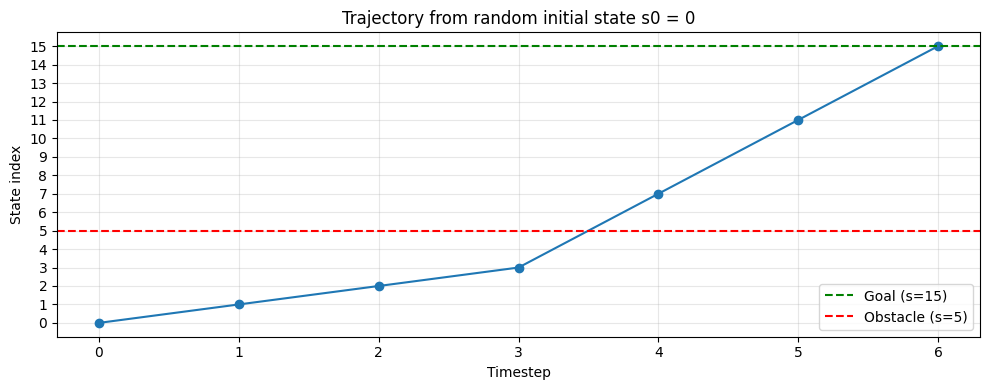

In [34]:
print(f"Episode length: {len(trajectory) - 1} steps")
print(f"Trajectory: {trajectory}")
print("Rewards per step: [" + ", ".join(f"{float(r):.2f}" for r in rewards) + "]")
print(f"Total reward: {float(total_reward):.2f}")
print(f"Discounted return (gamma={GAMMA}): {float(discounted_return):.3f}")
print(f"Reached goal: {trajectory[-1] == GOAL}")
plt.figure(figsize=(10, 4))
plt.plot(range(len(trajectory)), trajectory, marker='o', linewidth=1.5)
plt.axhline(GOAL, color='green', linestyle='--', label=f'Goal (s={GOAL})')
plt.axhline(OBSTACLE, color='red', linestyle='--', label=f'Obstacle (s={OBSTACLE})')
plt.xlabel('Timestep')
plt.ylabel('State index')
plt.title(f'Trajectory from random initial state s0 = {s0}')
plt.xticks(range(len(trajectory)))
plt.yticks(range(N_STATES))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


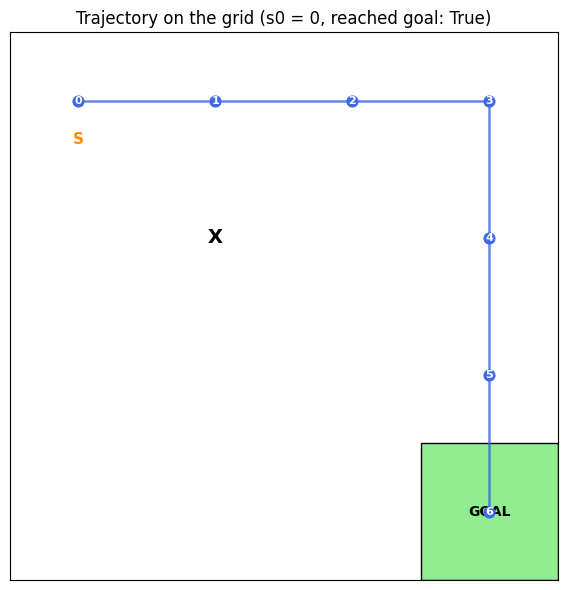

In [38]:
fig, ax = plt.subplots(figsize=(6, 6))
for r in range(ROWS):
    for c in range(COLS):
        s_cell = r * COLS + c
        if s_cell == GOAL:
            color = 'lightgreen'
        elif s_cell == OBSTACLE:
            color = 'lightgrey'
        elif s_cell == s0:
            color = 'blue'
        else:
            color = 'white'
ax.add_patch(plt.Rectangle((c, ROWS - 1 - r), 1, 1,
                facecolor=color, edgecolor='black'))
ax.text(divmod(GOAL, COLS)[1] + 0.5, ROWS - 1 - divmod(GOAL, COLS)[0] + 0.5,
    'GOAL', ha='center', va='center', fontsize=10, fontweight='bold')
ax.text(divmod(OBSTACLE, COLS)[1] + 0.5,
    ROWS - 1 - divmod(OBSTACLE, COLS)[0] + 0.5,
    'X', ha='center', va='center', fontsize=14, fontweight='bold')
xs = [divmod(s_cell, COLS)[1] + 0.5 for s_cell in trajectory]
ys = [ROWS - 1 - divmod(s_cell, COLS)[0] + 0.5 for s_cell in trajectory]
ax.plot(xs, ys, color='royalblue', linewidth=1.8, alpha=0.8, zorder=2)
ax.scatter(xs, ys, color='royalblue', s=60, zorder=3)

for t, (x, y) in enumerate(zip(xs, ys)):
    ax.text(x, y, str(t), ha='center', va='center',
        color='white', fontsize=8, fontweight='bold', zorder=4)

ax.text(xs[0], ys[0] - 0.28, 'S', ha='center', va='center',
fontsize=11, fontweight='bold', color='darkorange', zorder=5)
ax.set_xlim(0, COLS)
ax.set_ylim(0, ROWS)
ax.set_xticks(range(COLS + 1))
ax.set_yticks(range(ROWS + 1))
ax.set_aspect('equal')
ax.set_title(f'Trajectory on the grid (s0 = {s0}, reached goal: {trajectory[-1] == GOAL})')
ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
plt.tight_layout()
plt.show()

In [36]:
print("s0=", s0)
print("trajectory=" ,trajectory)
print("policy=", policy)

s0= 0
trajectory= [0, 1, 2, 3, 7, 11, 15]
policy= [1 1 1 2 1 0 3 2 1 1 1 2 1 1 1 0]


In [37]:
print(s0)
print(trajectory)

0
[0, 1, 2, 3, 7, 11, 15]
